# Évaluation de la détection : précision, rappel, F1

La fiche `baseline.md` mesure ce que coûte le modèle. Ce notebook mesure s'il **voit juste** : celui de l'application (MediaPipe Pose + seuils, réglages par défaut), sur les 4 enregistrements faits à un bureau.

- **Données** : `essais/donnees/<séance>/landmarks.jsonl`, soit les 33 repères MediaPipe de chaque image, sans aucune image (C7). Le dossier est exclu de git. Il y a 4 séances d'une même personne : 30 oct., puis 13 nov. A, B et C.
- **Vérité terrain** : la consigne de l'enregistrement (`essais/enregistrer.py`).
  - Mauvaise posture : tête en avant, avachi, penché.
  - Bonne posture : droit, droit2, regard vers le clavier.
  - Menton dans la main et trop près ne sont pas dans la tâche principale, car leurs détections sont désactivées par défaut. Ils reviennent au § 4.
- **Prédiction** : la vraie logique de l'application (`posture/detector.update_status`), rejouée par `essais/rejouer.py`. Mêmes réglages qu'à l'usage : calibration sur la médiane de « droit » entre 4 et 7 s, lissage sur 1 s, hystérésis, délai de 2 s. Chaque posture est rejouée seule, comme au banc.
- **Pas d'apprentissage** : aucun poids n'est entraîné, donc il n'y a pas de découpage entraînement / test. Le seul paramètre réglé sur des données est le seuil de 3 %, choisi sur la séance du 30 oct. Le § 3 montre ce qu'il vaut sur les autres.

À lancer depuis la racine du projet ou depuis `presentation/`, avec le noyau du `.venv` (MediaPipe 0.10.21).

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "posture").exists() else Path.cwd().parent
sys.path[:0] = [str(ROOT), str(ROOT / "essais")]
from rejouer import (CALIBRATION, CLASSES, LABELS, STEPS, app_class, expected_for,  # noqa: E402
                     reference, settings_for, simulate, wilson)

SEANCES = {"30 oct.": "2026-10-30", "13 nov. A": "2026-11-13-bureau-a",
           "13 nov. B": "2026-11-13-bureau-b", "13 nov. C": "2026-11-13-bureau-c"}
ATTENDU = expected_for(max(STEPS))  # posture -> (motifs requis, motifs admis), comme le banc
MAUVAISES = {p for p, (req, _) in ATTENDU.items() if req}
BONNES = {p for p, (req, _) in ATTENDU.items() if not req}

donnees = {}
for nom, dossier in SEANCES.items():
    lignes = [json.loads(l) for l in open(ROOT / "essais" / "donnees" / dossier / "landmarks.jsonl", encoding="utf-8")]
    ref = reference([r for r in lignes if r["posture"] == "droit" and CALIBRATION[0] <= r["t"] < CALIBRATION[1]])
    donnees[nom] = (lignes, ref)


def rejouer(nom, **reglages):
    """Chaque posture rejouee seule dans la logique de l'application, comme essais/rejouer.py."""
    lignes, ref = donnees[nom]
    s = settings_for(ref, overrides=reglages)
    return {p: simulate([r for r in lignes if r["posture"] == p], s) for p in dict.fromkeys(r["posture"] for r in lignes)}


print({nom: {p: len([r for r in l if r["posture"] == p]) for p in ATTENDU} for nom, (l, _) in donnees.items()})



{'30 oct.': {'droit': 359, 'droit2': 361, 'clavier': 359, 'tete_avant': 360, 'avache': 361, 'penche': 361}, '13 nov. A': {'droit': 263, 'droit2': 260, 'clavier': 263, 'tete_avant': 266, 'avache': 262, 'penche': 260}, '13 nov. B': {'droit': 269, 'droit2': 267, 'clavier': 262, 'tete_avant': 267, 'avache': 263, 'penche': 259}, '13 nov. C': {'droit': 250, 'droit2': 263, 'clavier': 244, 'tete_avant': 241, 'avache': 248, 'penche': 268}}


## 1. Image par image

Une image est **signalée** quand l'application la juge en mauvaise posture (état `bad` ou `alert`, délai d'alerte compris ou non). Positif = mauvaise posture.

- **Précision** : parmi les images signalées, la part de vraies mauvaises postures.
- **Rappel** : parmi les mauvaises postures, la part signalée.
- **Fausses alertes** : la part des bonnes postures signalées.

Entre crochets, l'intervalle de confiance de Wilson à 95 %.

In [2]:
def matrice(resultats):
    """Tache principale, image par image : signalee (etat « bad » ou « alert ») contre posture attendue."""
    c = Counter()
    for p, o in resultats.items():
        if p in ATTENDU:
            for st in o["frames"]:
                c[(p in MAUVAISES, st.get("state") in ("bad", "alert"))] += 1
    return c


def scores(c):
    vp, fn, fp, vn = c[(True, True)], c[(True, False)], c[(False, True)], c[(False, False)]
    precision = vp / (vp + fp) if vp + fp else float("nan")
    rappel = vp / (vp + fn)
    return {"VP": vp, "FN": fn, "FP": fp, "VN": vn, "precision": precision, "precision_ic": wilson(vp, vp + fp),
            "rappel": rappel, "rappel_ic": wilson(vp, vp + fn), "F1": 2 * precision * rappel / (precision + rappel),
            "fausses_alertes": fp / (fp + vn), "fausses_alertes_ic": wilson(fp, fp + vn)}


def ligne(nom, s):
    ic = lambda k: f"[{100 * s[k + '_ic'][0]:.1f}-{100 * s[k + '_ic'][1]:.1f}]"  # noqa: E731
    return (f"{nom:10} {s['VP']:5d} {s['FN']:5d} {s['FP']:5d} {s['VN']:5d}   {100 * s['precision']:5.1f} {ic('precision'):11}"
            f" {100 * s['rappel']:5.1f} {ic('rappel'):11} {s['F1']:.2f}  {100 * s['fausses_alertes']:5.1f} {ic('fausses_alertes')}")


defaut = {nom: rejouer(nom) for nom in SEANCES}
print(f"{'seance':10} {'VP':>5} {'FN':>5} {'FP':>5} {'VN':>5}   {'precision %':18} {'rappel %':17} {'F1':4}  fausses alertes %")
total = Counter()
for nom, res in defaut.items():
    c = matrice(res)
    total += c
    print(ligne(nom, scores(c)))
print(ligne("ensemble", scores(total)))



seance        VP    FN    FP    VN   precision %        rappel %          F1    fausses alertes %
30 oct.     1073     9    84   995    92.7 [91.1-94.1]  99.2 [98.4-99.6] 0.96    7.8 [6.3-9.5]
13 nov. A    478   310     0   786   100.0 [99.2-100.0]  60.7 [57.2-64.0] 0.76    0.0 [0.0-0.5]
13 nov. B    526   263    95   703    84.7 [81.7-87.3]  66.7 [63.3-69.9] 0.75   11.9 [9.8-14.3]
13 nov. C    657   100     0   757   100.0 [99.4-100.0]  86.8 [84.2-89.0] 0.93    0.0 [0.0-0.5]
ensemble    2734   682   179  3241    93.9 [92.9-94.7]  80.0 [78.7-81.3] 0.86    5.2 [4.5-6.0]


**Lecture**

- **Ensemble** : précision de 94 %, rappel de 80 %, F1 de 0,86, fausses alertes sur 5 % des images.
- **Les séances diffèrent beaucoup** : le rappel va de 61 % (A) à 99 % (30 oct.). Presque toutes les images ratées viennent de l'**avachi**, à 0 % dans A et dans B (SPECIFICATIONS § 6.6).
- **B, 12 % de fausses alertes** : surtout sur droit2 (32 % de ses images), parce que la calibration a été faite assis plus en arrière.
- **Les intervalles par image sont trop étroits.** Les images se suivent à 20 à 30 par seconde et se ressemblent : elles ne sont pas indépendantes, alors que Wilson le suppose. Le nombre d'observations honnête, c'est le nombre d'**épisodes** (§ 2).

## 2. Par épisode : ce que voit l'utilisateur

Un épisode est une posture tenue 12 s. Une mauvaise posture doit déclencher **au moins une alerte** (critère C2 « alerte »), une bonne posture **aucune** (C1).

In [3]:
print(f"{'seance':10} " + " ".join(f"{p:>11}" for p in ATTENDU))
ep = Counter()
for nom, res in defaut.items():
    cases = []
    for p in ATTENDU:
        if p not in res:
            cases.append(f"{'—':>11}")
            continue
        alerte = res[p]["alerts"] > 0
        ep[(p in MAUVAISES, alerte)] += 1
        cases.append(f"{('alerte' if alerte else 'rien') + (' ✓' if alerte == (p in MAUVAISES) else ' ✗'):>11}")
    print(f"{nom:10} " + " ".join(cases))
s = scores(ep)
print(f"\nPar episode : {s['VP']} mauvaises postures alertees sur {s['VP'] + s['FN']} "
      f"(rappel {100 * s['rappel']:.0f} %, IC {100 * s['rappel_ic'][0]:.0f}-{100 * s['rappel_ic'][1]:.0f} %), "
      f"{s['FP']} fausse(s) alerte(s) sur {s['FP'] + s['VN']} bonnes postures "
      f"(IC {100 * s['fausses_alertes_ic'][0]:.0f}-{100 * s['fausses_alertes_ic'][1]:.0f} %).")



seance           droit      droit2     clavier  tete_avant      avache      penche
30 oct.         rien ✓      rien ✓      rien ✓    alerte ✓    alerte ✓    alerte ✓
13 nov. A       rien ✓      rien ✓      rien ✓    alerte ✓      rien ✗    alerte ✓
13 nov. B       rien ✓      rien ✓      rien ✓    alerte ✓      rien ✗    alerte ✓
13 nov. C       rien ✓      rien ✓      rien ✓    alerte ✓    alerte ✓    alerte ✓

Par episode : 10 mauvaises postures alertees sur 12 (rappel 83 %, IC 55-95 %), 0 fausse(s) alerte(s) sur 12 bonnes postures (IC 0-24 %).


**Lecture**

- 10 mauvaises postures sur 12 déclenchent une alerte (83 %, intervalle de 55 à 95 %), et aucune bonne posture sur 12.
- Les 2 ratées sont l'avachi, dans A et dans B.
- Avec 12 épisodes de chaque côté, les intervalles restent larges. C'est la limite principale : une seule personne, 4 séances.

## 3. Sensibilité au seuil

Le seuil de raccourcissement de la hauteur tête-épaules (3 %) a été choisi le 30 oct., sur la première séance. Ici, on le fait varier de 1 à 8 % sur les 4 séances, sans rien changer d'autre.

Lignes pointillées : 3 % (verticale), et les objectifs de 90 % de rappel et de 10 % de fausses alertes (horizontales).

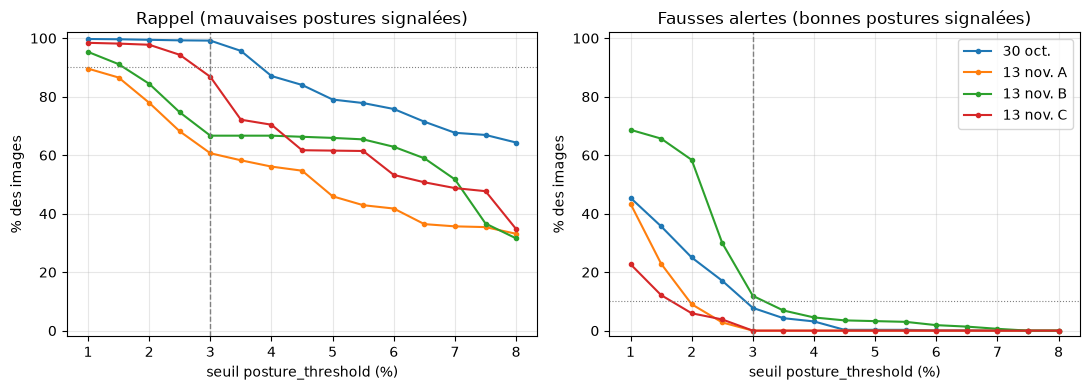

30 oct.    seuils avec rappel >= 90 % et fausses alertes <= 10 % : 3.0, 3.5
13 nov. A  seuils avec rappel >= 90 % et fausses alertes <= 10 % : aucun
13 nov. B  seuils avec rappel >= 90 % et fausses alertes <= 10 % : aucun
13 nov. C  seuils avec rappel >= 90 % et fausses alertes <= 10 % : 2.0, 2.5


In [4]:
import matplotlib.pyplot as plt

SEUILS = [i / 200 for i in range(2, 17)]  # 1 % a 8 % de raccourcissement
courbes = {nom: [scores(matrice(rejouer(nom, posture_threshold=t))) for t in SEUILS] for nom in SEANCES}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nom, sc in courbes.items():
    ax[0].plot([100 * t for t in SEUILS], [100 * s["rappel"] for s in sc], marker="o", ms=3, label=nom)
    ax[1].plot([100 * t for t in SEUILS], [100 * s["fausses_alertes"] for s in sc], marker="o", ms=3, label=nom)
for a, titre in zip(ax, ("Rappel (mauvaises postures signalées)", "Fausses alertes (bonnes postures signalées)")):
    a.axvline(3, color="grey", ls="--", lw=1)
    a.set(title=titre, xlabel="seuil posture_threshold (%)", ylabel="% des images", ylim=(-2, 102))
    a.grid(alpha=0.3)
ax[0].axhline(90, color="grey", lw=0.8, ls=":")
ax[1].axhline(10, color="grey", lw=0.8, ls=":")
ax[1].legend()
plt.tight_layout()
plt.show()
for nom, sc in courbes.items():
    ok = [f"{100 * t:.1f}" for t, s in zip(SEUILS, sc) if s["rappel"] >= 0.9 and s["fausses_alertes"] <= 0.1]
    print(f"{nom:10} seuils avec rappel >= 90 % et fausses alertes <= 10 % : {', '.join(ok) or 'aucun'}")



**Lecture**

- Un seuil qui remplit les deux objectifs n'existe que dans **2 séances sur 4** : 3 à 3,5 % le 30 oct., 2 à 2,5 % pour C.
- Dans A et B, **aucun seuil** n'y arrive. En s'avachissant, la hauteur tête-épaules ne raccourcit que de 1,6 à 1,8 %, autant que le bruit des bonnes postures.
- Le seuil n'est donc pas en cause, c'est la **mesure**. Il faut un autre signal pour l'avachi. Les pistes déjà écartées sont dans SPECIFICATIONS § 6.3, dont C15 (bascule de la tête), le 20 nov.

## 4. Motif : laquelle des 5 postures ?

Ici, toutes les détections sont activées (tête, trop près et main en plus), comme pour l'approche A de la comparaison C11 (SPECIFICATIONS § 4.6). La classe prédite est le motif prioritaire de l'application : trop près masque les autres, puis viennent la main, penché et affaissé. Tête en avant et avachi forment une seule classe, « affaissée », puisque l'application ne les distingue pas.

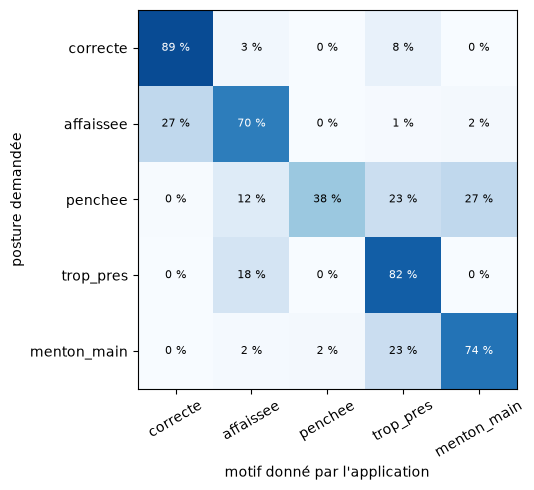

Motif exact sur 6889 images sur 9141 (75 %)
correcte     rappel du motif  89 %  sur 3420 images
affaissee    rappel du motif  70 %  sur 2268 images
penchee      rappel du motif  38 %  sur 1148 images
trop_pres    rappel du motif  82 %  sur 1149 images
menton_main  rappel du motif  74 %  sur 1156 images


In [5]:
TOUTES = {"detect_head": True, "detect_close": True, "detect_hand": True}
conf = Counter()
for nom in SEANCES:
    for p, o in rejouer(nom, **TOUTES).items():
        if p in LABELS:
            conf.update((LABELS[p], app_class(st)) for st in o["frames"])
m = [[conf[(v, pr)] for pr in CLASSES] for v in CLASSES]
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow([[x / max(1, sum(r)) for x in r] for r in m], cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(xlabel="motif donné par l'application", ylabel="posture demandée")
for i, r in enumerate(m):
    for j, x in enumerate(r):
        ax.text(j, i, f"{100 * x / max(1, sum(r)):.0f} %", ha="center", va="center", fontsize=8,
                color="white" if x > 0.6 * sum(r) else "black")
plt.tight_layout()
plt.show()
juste = sum(m[i][i] for i in range(len(CLASSES)))
print(f"Motif exact sur {juste} images sur {sum(map(sum, m))} ({100 * juste / sum(map(sum, m)):.0f} %)")
for v, r in zip(CLASSES, m):
    print(f"{v:12} rappel du motif {100 * r[CLASSES.index(v)] / max(1, sum(r)):3.0f} %  sur {sum(r)} images")


**Lecture**

- Le motif est exact sur 75 % des images.
- Par classe : correcte 89 %, trop près 82 %, menton dans la main 74 %, affaissée 70 %, penchée 38 %.
- **Penché, confondu avec menton dans la main** (30 oct. et A) : s'accouder rapproche la main du visage.
- **Dans B, penché et menton dans la main deviennent « trop près »** : la calibration faite assis plus en arrière fait paraître les épaules plus larges ensuite.
- C'est pourquoi ces détections restent désactivées par défaut.

## 5. Limites et reproduction

- **Une seule personne, une webcam, 4 séances** : ces chiffres ne disent rien d'autres personnes. Le protocole pour en enregistrer d'autres est prêt : `essais/dataset_video.md` et `essais/enregistrer.py`.
- **Aucun jeu public ne les remplace** (relevé le 13 nov. 2026). [SENSE-42](https://doi.org/10.25452/figshare.plus.29973202) filme de vraies tâches de bureau à la webcam (41 personnes, 1280×720, sessions d'environ 2 h), mais sur demande, avec un casque EEG, et sans étiquette de posture. [DAiSEE](https://people.iith.ac.in/vineethnb/resources/daisee/index.html) est public (112 personnes, webcam 1080p, 30 images/s) : les personnes regardent des vidéos, les étiquettes sont l'engagement. [Edinburgh Office](https://homepages.inf.ed.ac.uk/rbf/OFFICEDATA/) est un vrai bureau, filmé par une caméra de pièce à environ 1 image/s. Le jeu généré du dépôt ne compte pas non plus : 0 échec au banc sur 16 séries, contre 8 ici.
- La calibration utilise des images de « droit » (de 4 à 7 s) qui sont aussi notées, ce qui avantage un peu « droit ».
- Les images ne sont pas indépendantes (§ 1) : il faut lire les épisodes (§ 2) avant les images.
- **Recoupement** : les pourcentages par posture sont ceux de `essais/rejouer.py` (8 critères non atteints sur les 4 séances, SPECIFICATIONS § 6.6).
- **Reproduction** : les enregistrements ne sont pas dans git (C7). Sur le poste qui les a, il faut installer `ipykernel` dans le `.venv`, puis exécuter le notebook avec ce noyau.